**Import modules**

In [26]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.model_selection import train_test_split
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import numpy as np
import matplotlib.pyplot as plt
from mlxtend.plotting import plot_decision_regions


**Load and prepare data**


In [27]:
wine = load_wine()

X_train, X_test, y_train, y_test = train_test_split(
    wine.data, wine.target, test_size=0.3,
    stratify=wine.target, random_state=0)

#==============================================================================
# Scale features using StandardScaler class in scikit-learn
#==============================================================================
# Initialise standard scaler and compute mean and STD from training data
sc = StandardScaler()
sc.fit(X_train)

# Transform (standardise) both X_train and X_test with mean and STD from
# training data
X_train_std = sc.transform(X_train)
X_test_std = sc.transform(X_test)


**Apply LDA to data**


In [47]:

# create model
lda = LDA(n_components=2)

# fit and transform training data
X_train_lda = lda.fit_transform(X_train_std, y_train)

# transform test data
X_test_lda = lda.transform(X_test_std)

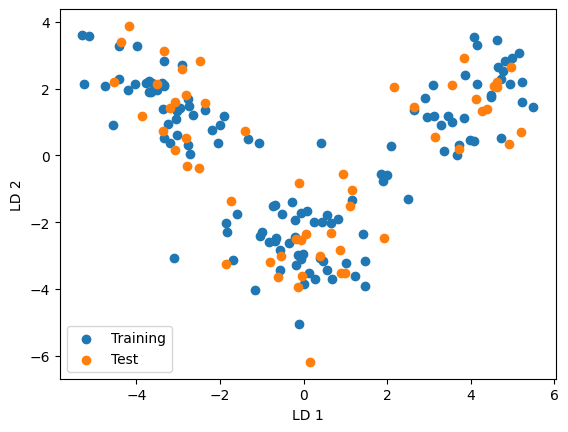

In [48]:
plt.scatter(X_train_lda[:, 0], X_train_lda[:, 1], label="Training")
plt.scatter(X_test_lda[:, 0],  X_test_lda[:, 1],  label="Test")
plt.xlabel('LD 1')
plt.ylabel('LD 2')
plt.legend()
plt.show()

**Train logistic regression classifier with LDA components/features**

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


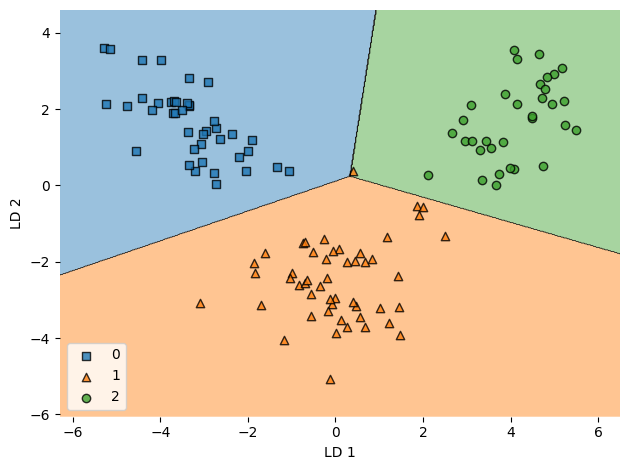

In [49]:
# solver='liblinear': Specifies the optimization algorithm used to find the best model parameters.
# multi_class='auto': Determines how to handle multi-class classification. Since 'liblinear' is used, it defaults to one-vs-rest (OvR) for multi-class classification.
lr = LogisticRegression(solver='liblinear', multi_class='auto')
lr = lr.fit(X_train_lda, y_train)

# =============================================================================
# Plot decision regions with training samples
# =============================================================================
plot_decision_regions(X_train_lda, y_train, clf=lr)
plt.xlabel('LD 1')
plt.ylabel('LD 2')
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()



In [50]:


print('\nLDA - logReg - TRAIN accuracy = {0:.3f}'.format(lr.score(X_train_lda, y_train)))
print('LDA - logReg - TEST accuracy = {0:.3f}'.format(lr.score(X_test_lda, y_test)))




LDA - logReg - TRAIN accuracy = 0.992
LDA - logReg - TEST accuracy = 1.000


**Predict directly using LDA**

In [51]:
y_pred_dir = lda.predict(X_test_std)
print(lda.score(X_test_std, y_test))

1.0


In [52]:
# lda.coef_ contains the coefficients of the linear decision boundary used for classification.

# They are the weights applied to each feature to compute the classification score.

# These weights define the hyperplane that separates the classes.

lda.coef_

array([[ 2.42480868e+00, -2.36945470e-01,  1.13325308e+00,
        -2.14043558e+00,  3.47887889e-01, -1.68359346e+00,
         4.69584937e+00,  6.24912984e-01, -2.66671011e-01,
        -1.87173379e+00, -5.12616323e-01,  2.62362586e+00,
         4.85428471e+00],
       [-1.79509540e+00, -7.88596495e-01, -1.51981406e+00,
         1.36583107e+00, -2.81260705e-01,  3.35418020e-01,
         1.27013594e+00, -1.03869972e-02,  3.13802300e-01,
        -1.20031969e+00,  1.06462208e+00, -2.26015497e-01,
        -2.57036578e+00],
       [-2.92799573e-01,  1.48922997e+00,  8.94767479e-01,
         5.89888034e-01, -6.07176269e-03,  1.58352820e+00,
        -7.75868550e+00, -7.60669167e-01, -1.44139501e-01,
         4.14415363e+00, -9.76176813e-01, -2.91720865e+00,
        -2.13658740e+00]])

# **Discussion Questions:**




**1. A dataset has 7 features and 5 classes. What is the maximum number of LDA components allowed, and why?**

**2. Try LDA(n_components=1), what is your observation?**




**Kernel PCA**

**Example 1: Separating half-moon shapes**

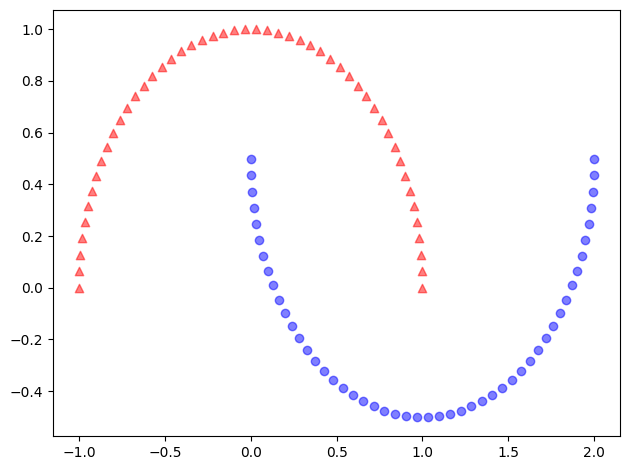

In [34]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=100, random_state=123)

plt.scatter(X[y == 0, 0], X[y == 0, 1], color='red', marker='^', alpha=0.5)
plt.scatter(X[y == 1, 0], X[y == 1, 1], color='blue', marker='o', alpha=0.5)

plt.tight_layout()
plt.show()

**Ordinary PCA**

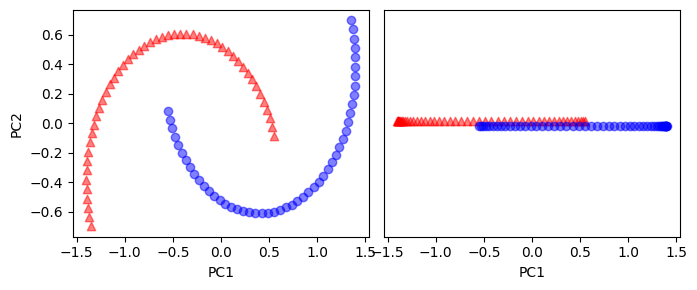

In [35]:
from sklearn.decomposition import PCA

scikit_pca = PCA(n_components=2)
X_spca = scikit_pca.fit_transform(X)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(7, 3))

# Plot scores 1 and 2
ax[0].scatter(X_spca[y == 0, 0], X_spca[y == 0, 1],
              color='red', marker='^', alpha=0.5)
ax[0].scatter(X_spca[y == 1, 0], X_spca[y == 1, 1],
              color='blue', marker='o', alpha=0.5)

# Still not separable in any direction (check PC 2)
pc = 1
ax[1].scatter(X_spca[y == 0, pc-1], np.zeros((50, 1)) + 0.02,
              color='red', marker='^', alpha=0.5)
ax[1].scatter(X_spca[y == 1, pc-1], np.zeros((50, 1)) - 0.02,
              color='blue', marker='o', alpha=0.5)

ax[0].set_xlabel('PC1')
ax[0].set_ylabel('PC2')
ax[1].set_ylim([-1, 1])
ax[1].set_yticks([])
ax[1].set_xlabel('PC'+str(pc))

plt.tight_layout()
plt.show()



**Kernel PCA**

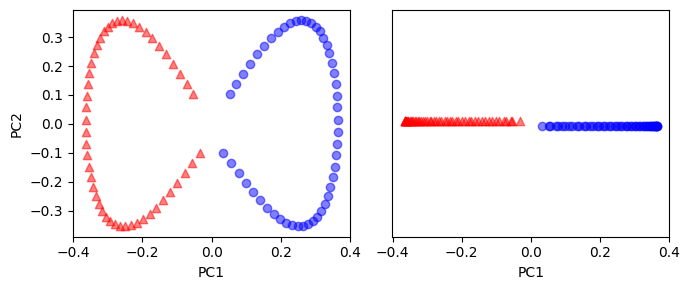

In [36]:
from sklearn.decomposition import KernelPCA
import numpy as np
import matplotlib.pyplot as plt

# Apply Kernel PCA
kpca = KernelPCA(n_components=2, kernel="rbf", gamma=15)
X_kpca = kpca.fit_transform(X)

# Plot
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(7, 3))

# 2D projection
ax[0].scatter(X_kpca[y == 0, 0], X_kpca[y == 0, 1],
              color='red', marker='^', alpha=0.5)
ax[0].scatter(X_kpca[y == 1, 0], X_kpca[y == 1, 1],
              color='blue', marker='o', alpha=0.5)

# 1D projection on first component
pc = 1
ax[1].scatter(X_kpca[y == 0, pc - 1], np.zeros(sum(y == 0)) + 0.02,
              color='red', marker='^', alpha=0.5)
ax[1].scatter(X_kpca[y == 1, pc - 1], np.zeros(sum(y == 1)) - 0.02,
              color='blue', marker='o', alpha=0.5)

ax[0].set_xlabel('PC1')
ax[0].set_ylabel('PC2')
ax[1].set_xlabel(f'PC{pc}')
ax[1].set_yticks([])
ax[1].set_ylim([-1, 1])

plt.tight_layout()
plt.show()

**Logistic regression on raw data**

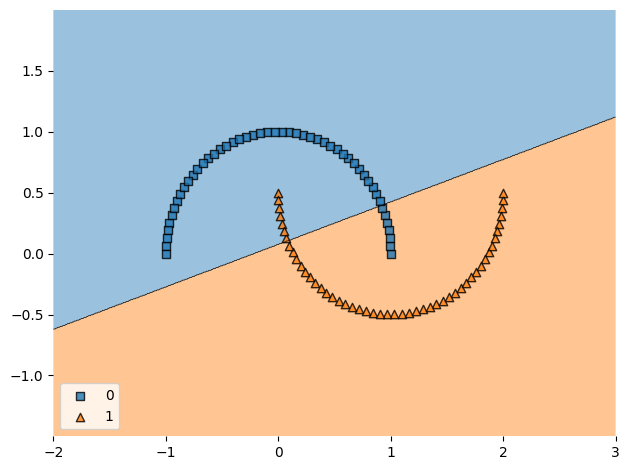

In [37]:


from mlxtend.plotting import plot_decision_regions
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(solver = 'lbfgs')
lr = lr.fit(X, y)

plot_decision_regions(X, y, clf = lr)
plt.legend(loc='lower left')
plt.tight_layout()
plt.show()



**Logistic regression on transformed data**

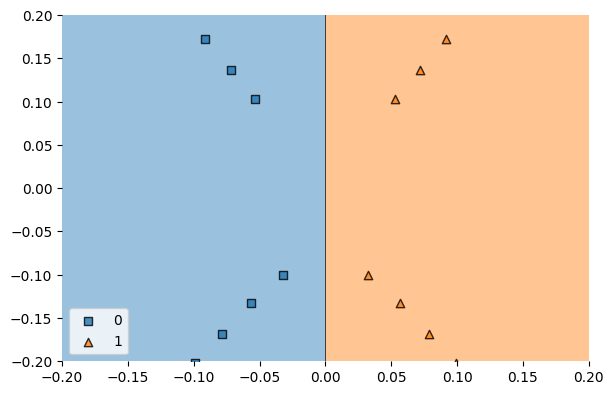

In [38]:
from sklearn.linear_model import LogisticRegression
# LBFGS is an optimization algorithm that approximates the Hessian matrix to efficiently solve large-scale numerical optimization problems, commonly used in machine learning for models like logistic regression.
lr = LogisticRegression(solver = 'lbfgs')
lr = lr.fit(X_kpca, y)

# Plot Decision Regions
plt.figure(figsize=(6, 4))
plot_decision_regions(X_kpca, y, clf=lr)
plt.legend(loc='lower left')
plt.tight_layout()
plt.xlim([-0.2, 0.2])
plt.ylim([-0.2, 0.2])
plt.show()